# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

**Виконав:** Харченко Артьом, група ФІТ 3-10

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

Ознаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']


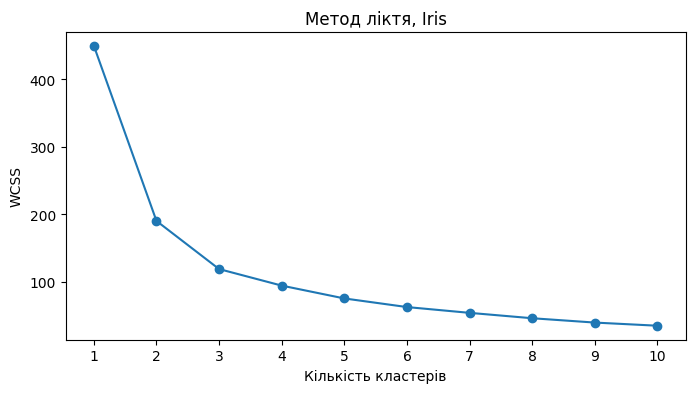

WCSS: [450.0, 190.5, 119.1, 94.6, 75.6, 62.9, 54.3, 46.3, 39.9, 35.2]


In [3]:
# беремо перші три ознаки Iris
features = iris_df.iloc[:, :3]
print("Ознаки:", features.columns.tolist())

scaler_iris = StandardScaler()
X_iris = scaler_iris.fit_transform(features)

# WCSS (inertia) для 1-10 кластерів
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_iris)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Метод ліктя, Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.show()

print("WCSS:", [round(w, 1) for w in wcss])

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

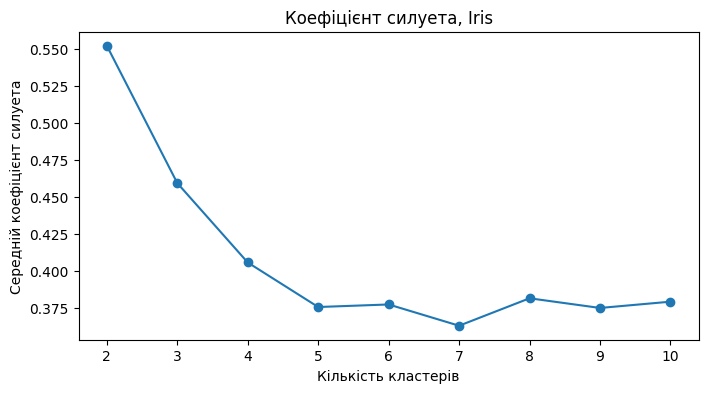

k = 2: 0.552
k = 3: 0.459
k = 4: 0.406
k = 5: 0.375
k = 6: 0.377
k = 7: 0.363
k = 8: 0.381
k = 9: 0.375
k = 10: 0.379


In [4]:
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_iris)
    sil_scores.append(silhouette_score(X_iris, labels))

plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), sil_scores, marker="o")
plt.title("Коефіцієнт силуета, Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(range(2, 11))
plt.show()

for k, s in zip(range(2, 11), sil_scores):
    print(f"k = {k}: {s:.3f}")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

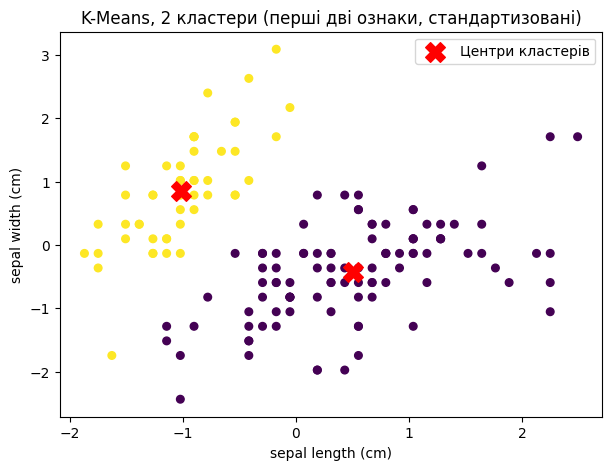

Розміри кластерів: {0: 100, 1: 50}
Центри (за трьома ознаками, стандартизовані):
   sepal length (cm)  sepal width (cm)  petal length (cm)
0              0.507            -0.427              0.652
1             -1.015             0.853             -1.305


In [5]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
iris_labels = kmeans.fit_predict(X_iris)
centers = kmeans.cluster_centers_

plt.figure(figsize=(7, 5))
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=iris_labels, cmap="viridis", s=30)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200, label="Центри кластерів")
plt.title("K-Means, 2 кластери (перші дві ознаки, стандартизовані)")
plt.xlabel(features.columns[0])
plt.ylabel(features.columns[1])
plt.legend()
plt.show()

print("Розміри кластерів:", pd.Series(iris_labels).value_counts().to_dict())
print("Центри (за трьома ознаками, стандартизовані):")
print(pd.DataFrame(centers, columns=features.columns).round(3))

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Відповідь:** на графіку ліктя WCSS різко падає від 1 до 2 кластерів (450 і 190), потім до 3 кластерів (119), далі падіння повільніше. Чіткого злому немає, лікоть виглядає десь між 2 і 3 кластерами. На графіку силуетів найвище значення при 2 кластерах (0.552), при 3 воно вже менше (0.459), а далі ще нижче.

Тому вибрали 2 кластери: цей вибір збігається з силуетом (там максимум) і не суперечить ліктю. Кластери вийшли розміром 100 і 50. Менший кластер це ірис setosa, він сильно відрізняється від решти, а два інші види між собою схожі, тому K-Means об'єднав їх в один кластер. Хоча в Iris справжніх видів три, за цими трьома ознаками чітко розділяються тільки два кластери.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print("Пропусків:", df.isnull().sum().sum())
df.isnull().sum()

Пропусків: 0


,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Дублікатів:", df.duplicated().sum())

Дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=["GradeClass", "StudentID"])
y = df["GradeClass"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# scaler навчаємо тільки на train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Класи в y_train:", y_train.value_counts().sort_index().to_dict())

Train: (1913, 13) | Test: (479, 13)
Класи в y_train: {0: 85, 1: 220, 2: 306, 3: 328, 4: 974}


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring="accuracy", n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

rf_test_acc = accuracy_score(y_test, rf_grid.predict(X_test_scaled))
print("Найкращі параметри:", rf_grid.best_params_)
print("CV-точність:", round(rf_grid.best_score_, 4))
print("Тестова accuracy:", round(rf_test_acc, 4))

Найкращі параметри: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
CV-точність: 0.9237
Тестова accuracy: 0.9144


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
lr_params = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["saga"],
    "max_iter": [5000],
}

lr_grid = GridSearchCV(LogisticRegression(), lr_params, cv=5, scoring="accuracy", n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

lr_test_acc = accuracy_score(y_test, lr_grid.predict(X_test_scaled))
print("Найкращі параметри:", lr_grid.best_params_)
print("CV-точність:", round(lr_grid.best_score_, 4))
print("Тестова accuracy:", round(lr_test_acc, 4))

Найкращі параметри: {'C': 10, 'max_iter': 5000, 'solver': 'saga'}
CV-точність: 0.7898
Тестова accuracy: 0.7432


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm_params = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
}

svm_grid = GridSearchCV(SVC(), svm_params, cv=5, scoring="accuracy", n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

svm_test_acc = accuracy_score(y_test, svm_grid.predict(X_test_scaled))
print("Найкращі параметри:", svm_grid.best_params_)
print("CV-точність:", round(svm_grid.best_score_, 4))
print("Тестова accuracy:", round(svm_test_acc, 4))

Найкращі параметри: {'C': 10, 'kernel': 'linear'}
CV-точність: 0.862
Тестова accuracy: 0.8288


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
comparison = pd.DataFrame({
    "Модель": ["Random Forest", "Logistic Regression", "SVM"],
    "CV-точність": [rf_grid.best_score_, lr_grid.best_score_, svm_grid.best_score_],
    "Тестова accuracy": [rf_test_acc, lr_test_acc, svm_test_acc],
})
display(comparison.round(4))

# модель обираємо за CV-точністю
grids = {"Random Forest": rf_grid, "Logistic Regression": lr_grid, "SVM": svm_grid}
best_name = comparison.loc[comparison["CV-точність"].idxmax(), "Модель"]
print("Найкраща модель за CV-точністю:", best_name)

print(classification_report(y_test, grids[best_name].predict(X_test_scaled)))

,Модель,CV-точність,Тестова accuracy
0,Random Forest,0.9237,0.9144
1,Logistic Regression,0.7898,0.7432
2,SVM,0.8620,0.8288


Найкраща модель за CV-точністю: Random Forest
              precision    recall  f1-score   support

           0       0.83      0.45      0.59        22
           1       0.81      0.88      0.84        49
           2       0.94      0.87      0.90        85
           3       0.90      0.90      0.90        86
           4       0.94      0.99      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.82      0.84       479
weighted avg       0.91      0.91      0.91       479



**Висновок:** найкращою за CV-точністю виявився Random Forest: CV-точність 0.924, на тесті accuracy 0.914. SVM гірший (0.862 і 0.829), а логістична регресія найгірша (0.790 і 0.743). Тобто залежність між ознаками і оцінкою нелінійна, і дерева її ловлять краще за лінійну модель.

У звіті видно, що найгірше модель визначає клас 0 (recall лише 0.45), бо таких студентів мало (22 на тесті). Найкраще визначається клас 4, найбільший (recall 0.99).

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

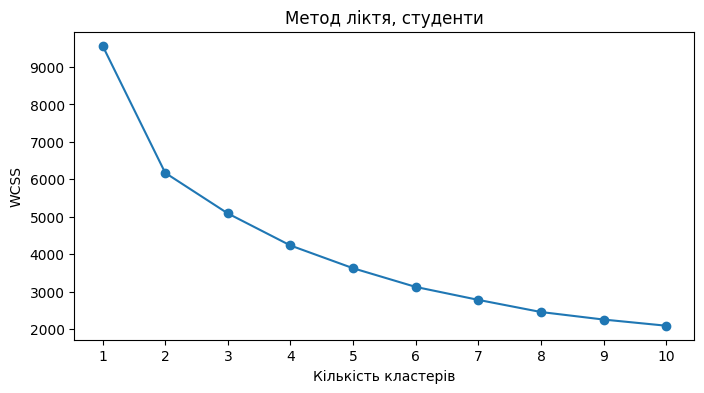

WCSS: [9568, 6170, 5086, 4229, 3622, 3122, 2776, 2452, 2251, 2086]


In [19]:
cluster_cols = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
X_students = StandardScaler().fit_transform(df[cluster_cols])

wcss_st = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_students)
    wcss_st.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss_st, marker="o")
plt.title("Метод ліктя, студенти")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.show()

print("WCSS:", [round(w) for w in wcss_st])

**Висновок:** на графіку ліктя немає чіткого злому, WCSS плавно зменшується від 9568 при 1 кластері до 2086 при 10. Тобто за цими ознаками чітких груп студентів немає.

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

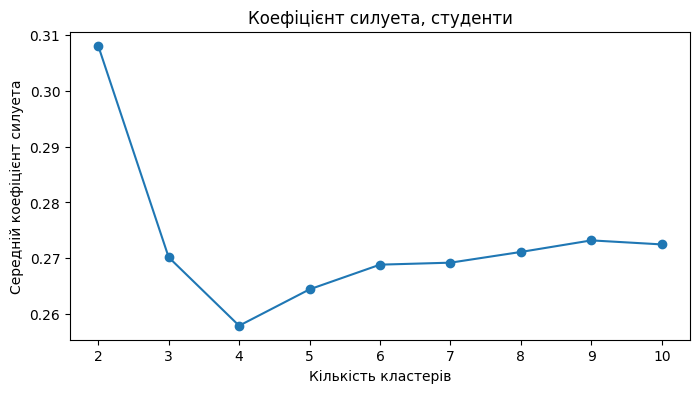

k = 2: 0.308
k = 3: 0.270
k = 4: 0.258
k = 5: 0.264
k = 6: 0.269
k = 7: 0.269
k = 8: 0.271
k = 9: 0.273
k = 10: 0.272


In [20]:
sil_st = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    sil_st.append(silhouette_score(X_students, km.fit_predict(X_students)))

plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), sil_st, marker="o")
plt.title("Коефіцієнт силуета, студенти")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(range(2, 11))
plt.show()

for k, s in zip(range(2, 11), sil_st):
    print(f"k = {k}: {s:.3f}")

**Висновок:** найбільший коефіцієнт силуета при 2 кластерах (0.308), але він невеликий, при інших k значення близько 0.26-0.27. Значення менше 0.5 означає, що кластери розділені слабо і сильно перекриваються. Метод силуетів пропонує 2 кластери, але впевненості в цьому немає.

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
%pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_all = df.drop(columns=["StudentID", "GradeClass"])
print("Ознак для PCA:", X_all.shape[1])
print(X_all.columns.tolist())

Ознак для PCA: 13
['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
X_all_scaled = StandardScaler().fit_transform(X_all)

pca = PCA()
pca.fit(X_all_scaled)
explained = pca.explained_variance_ratio_

for i, v in enumerate(explained, start=1):
    print(f"Компонента {i}: {v:.3f}")

Компонента 1: 0.152
Компонента 2: 0.086
Компонента 3: 0.083
Компонента 4: 0.081
Компонента 5: 0.079
Компонента 6: 0.078
Компонента 7: 0.076
Компонента 8: 0.076
Компонента 9: 0.074
Компонента 10: 0.074
Компонента 11: 0.072
Компонента 12: 0.067
Компонента 13: 0.002


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

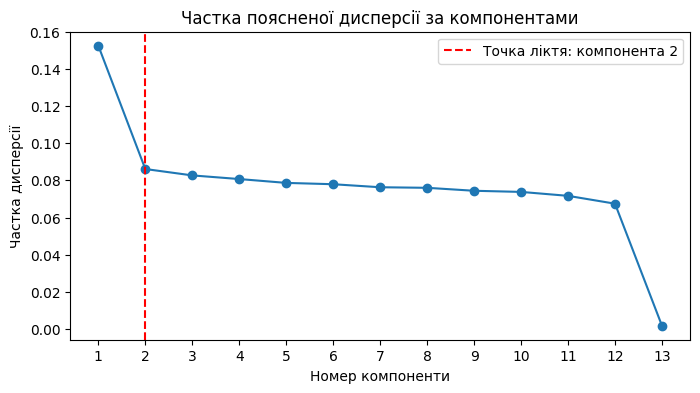

Обрано компонент: 2


In [25]:
components = range(1, len(explained) + 1)

knee = KneeLocator(components, explained, curve="convex", direction="decreasing")
n_components = knee.knee

plt.figure(figsize=(8, 4))
plt.plot(components, explained, marker="o")
plt.axvline(n_components, color="red", linestyle="--", label=f"Точка ліктя: компонента {n_components}")
plt.title("Частка поясненої дисперсії за компонентами")
plt.xlabel("Номер компоненти")
plt.ylabel("Частка дисперсії")
plt.xticks(components)
plt.legend()
plt.show()

print("Обрано компонент:", n_components)

Для PCA в усіх ознак були обчислені частки поясненої дисперсії. Перша компонента пояснює 15.2%, а наступні майже однакові (7-8% кожна), остання майже нічого (0.2%). KneeLocator визначив точку ліктя на 2 компонентах.

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

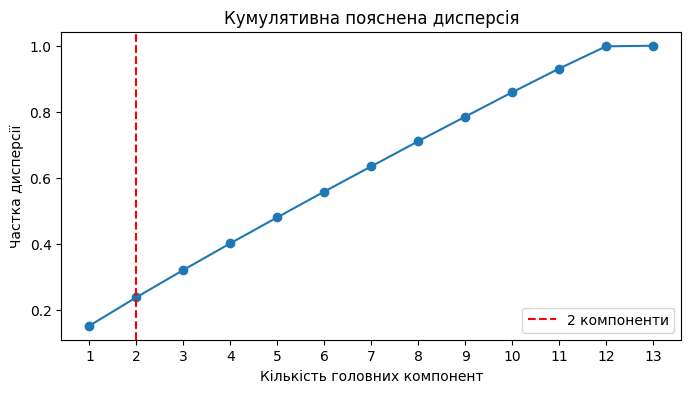

2 компоненти пояснюють 0.239 дисперсії (23.9%)
Розмір даних після PCA: (2392, 2)


In [26]:
cumulative = np.cumsum(explained)

plt.figure(figsize=(8, 4))
plt.plot(components, cumulative, marker="o")
plt.axvline(n_components, color="red", linestyle="--", label=f"{n_components} компоненти")
plt.title("Кумулятивна пояснена дисперсія")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Частка дисперсії")
plt.xticks(components)
plt.legend()
plt.show()

# індекс = n_components - 1, бо компоненти нумеруються з 1
share = cumulative[n_components - 1]
print(f"{n_components} компоненти пояснюють {share:.3f} дисперсії ({share * 100:.1f}%)")

pca_final = PCA(n_components=n_components)
X_pca = pca_final.fit_transform(X_all_scaled)
print("Розмір даних після PCA:", X_pca.shape)

**Висновок:** 2 головні компоненти пояснюють тільки 23.9% дисперсії. Це мало, тобто PCA тут стискає дані погано: ознаки майже не пов'язані між собою, тому інформація розподілена порівну по багатьох компонентах (щоб пояснити понад 90%, треба 11 компонент з 13).

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

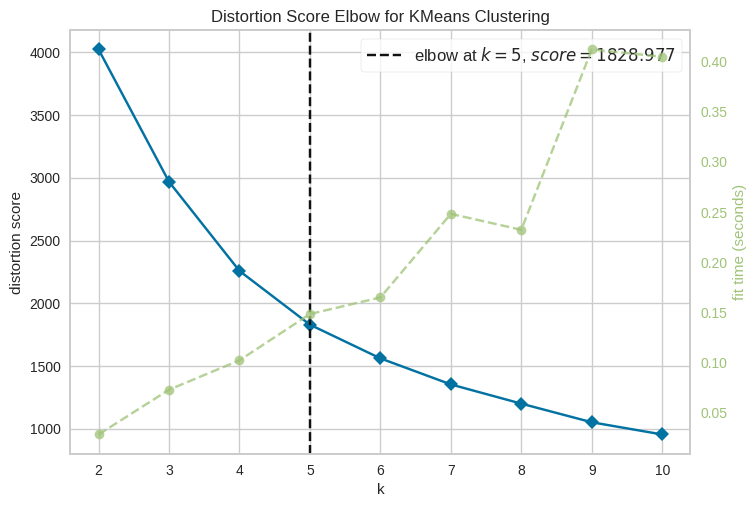

Оптимальна кількість кластерів за KElbowVisualizer: 5


In [28]:
visualizer = KElbowVisualizer(KMeans(n_init=10, random_state=42), k=(2, 11))
visualizer.fit(X_pca)
visualizer.show()

print("Оптимальна кількість кластерів за KElbowVisualizer:", visualizer.elbow_value_)

**Висновок:** KElbowVisualizer на даних після PCA (2 компоненти) запропонував 5 кластерів, тобто результат відрізняється від методу силуетів (там було 2). Це ще раз показує, що чіткої кластерної структури в даних студентів немає.

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

**Завдання 1 (Iris).** Метод ліктя дав лікоть між 2 і 3 кластерами, метод силуетів показав максимум при 2 кластерах (0.552). Вибрали 2 кластери: вони відокремлюють ірис setosa від двох інших схожих видів.

**Завдання 2 (студенти).**
- Класифікація і кластеризація це різні задачі. У класифікації ми знаємо правильну відповідь GradeClass і вчимо модель її передбачати: найкращий результат у Random Forest (accuracy 0.914 на тесті, CV 0.924), далі SVM (0.829) і логістична регресія (0.743). У кластеризації цільової змінної немає, K-Means просто групує студентів за схожістю ознак, а правильних відповідей для перевірки немає, тому якість оцінюємо силуетом.
- Кластеризація студентів за ознаками Age, StudyTimeWeekly, Absences, GPA дала слабкі результати: на ліктях немає чіткого злому, найкращий силует 0.308 при 2 кластерах.
- PCA: за ліктем (KneeLocator) вибрано 2 головні компоненти, вони пояснюють 23.9% дисперсії. Це мало, бо ознаки між собою слабо пов'язані. Після PCA метод KElbowVisualizer запропонував 5 кластерів.
- Тому різні способи визначення кількості кластерів дають різні відповіді (2 за силуетом, 5 після PCA), і для студентів чіткої кластерної структури немає.